# Integrated Threat Intelligence & Vulnerability Prioritization Suite
### Combining IBM Granite Embeddings, Point-in-Time Telemetry, and Interactive Analysis

This notebook merges the unique approaches from both team workflows:
1. **Exploratory Analytics & CVSS Deep Dive** (from Attila's analysis)
2. **Point-in-Time Anti-Leakage Feature Engineering & Granite Latent Embeddings** (from Xavier's analysis)
3. **Interactive Mode Selector**: Allows the user to toggle dynamically between:
   - **Summary**: Plain-English plain-text summaries of severe CVEs using IBM Granite (`ibm-granite/granite-4.0-micro` or Gemini).
   - **Prediction**: Threat-informed composite scoring & generation of `top500.csv` based on point-in-time exploit signals.
   - **Visualization**: Statistical breakdowns, EPSS distribution curves, exploit telemetry comparisons, and attack-vector risk heatmaps.

In [3]:
# Cell 1: Environment Setup & Package Imports
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from dotenv import load_dotenv
import os
import gzip


# Load environment variables (.env)
load_dotenv()

# Optional AI integrations (handled safely if keys/packages are absent)
try:
    from google import genai
    gemini_available = bool(os.getenv("GEMINI_API_KEY"))
    if gemini_available:
        gemini_client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
    else:
        gemini_client = None
except ImportError:
    gemini_client = None
    gemini_available = False

print(f"Setup completed. Gemini API ready: {gemini_available}")

# ElevenLabs Initialization
try:
  from elevenlabs import ElevenLabs

  eleven_api_key = os.getenv("ELEVENLABS_API_KEY")
  eleven_available = bool(eleven_api_key)
  if eleven_available:
    eleven_client = ElevenLabs(api_key=eleven_api_key)
  else:
    eleven_client = None
except ImportError:
  eleven_client = None
  eleven_available = False

print(f"ElevenLabs ready: {eleven_available}")

Setup completed. Gemini API ready: False
ElevenLabs ready: False


In [4]:
# Cell 2: Data Ingestion with Schema Protection
print("Loading core datasets from data/...")
vul = pd.read_csv("data/vulnerabilities.csv.gz")
scoreBoard = pd.read_csv("data/scoreboard_2026.csv.gz")
knownExploits = pd.read_csv("data/known_exploited.csv.gz")
weaknesses = pd.read_csv("data/weakness_types.csv.gz")

# Read signals if needed for deeper historical context
# exploitSignals = pd.read_csv("data/exploit_signals_2024.csv.gz")
# exploitSignals2 = pd.read_csv("data/exploit_signals_2025.csv.gz")

# Load precomputed 768-dim IBM Granite Embeddings if available
embeddings = None
embedding_path = "data/granite_embeddings.npy"

if os.path.exists(embedding_path):
    embeddings = np.load(embedding_path)
    print(f"Loaded Granite embeddings: {embeddings.shape}")
elif os.path.exists("data/granite_embeddings.npy.gz"):
    # FIX: Open with gzip block first, then pass the file handle to np.load
    with gzip.open("data/granite_embeddings.npy.gz", "rb") as f:
        embeddings = np.load(f, allow_pickle=True)
    print(f"Loaded Granite embeddings (compressed): {embeddings.shape}")
else:
    print("Note: granite_embeddings.npy not found in data/. Fallback heuristic scoring will be used.")

print(f"Loaded {len(vul):,} total CVEs and {len(scoreBoard):,} 2026 scoreboard candidates.")

Loading core datasets from data/...
Loaded Granite embeddings (compressed): (72670, 768)
Loaded 401,082 total CVEs and 72,670 2026 scoreboard candidates.


In [5]:
# Cell 3: Anti-Leakage Feature Extraction & Scoring Engine (Xavier's Pipeline)
def prepare_feature_pipeline():
    """
    Constructs point-in-time features strictly avoiding target leakage 
    (omitting nvd_status, n_affected_cpes, n_references, post-attack links).
    """
    df = scoreBoard.copy()
    metadata_cols = [c for c in ['cve_id', 'description', 'cwe_ids', 'assigner', 'cvss3_score', 'attack_vector'] if c in vul.columns]
    df = df.merge(vul[metadata_cols], on='cve_id', how='left')
    df['description'] = df['description'].fillna('')
    df['epss'] = df['epss'].fillna(0.0)
    
    # Heuristic text patterns
    desc_lower = df['description'].str.lower()
    df['is_rce'] = desc_lower.str.contains(r'remote code execution|execute arbitrary code|command injection', regex=True).astype(int)
    df['is_auth_bypass'] = desc_lower.str.contains(r'bypass authentication|unauthenticated|improper authentication', regex=True).astype(int)
    df['is_perimeter'] = desc_lower.str.contains(r'vpn|firewall|gateway|router|appliance|citrix|fortinet|palo alto|ivanti', regex=True).astype(int)
    
    # Public exploit weaponization flags
    df['any_exploit'] = ((df['poc_github'] == 1) | (df['nuclei'] == 1) | (df['exploitdb'] == 1) | (df['metasploit'] == 1)).astype(int)
    
    # High-risk CWE flags
    high_risk_cwes = ['CWE-77', 'CWE-78', 'CWE-502', 'CWE-287', 'CWE-306', 'CWE-22', 'CWE-89']
    df['high_risk_cwe'] = df['cwe_ids'].fillna('').apply(lambda x: int(any(cwe in str(x) for cwe in high_risk_cwes)))
    
    # Semantic vector component
    if embeddings is not None and embeddings.shape[0] == len(df):
        direction = embeddings.mean(axis=0)
        df['semantic_score'] = embeddings @ direction
    else:
        df['semantic_score'] = 0.0
        
    # Composite threat score
    df['prediction_score'] = (
        (df['epss'] * 4.0) +
        (df['any_exploit'] * 3.0) +
        (df['poc_github'] * 2.0) +
        (df['is_perimeter'] * 2.5) +
        (df['is_rce'] * 2.0) +
        (df['is_auth_bypass'] * 1.5) +
        (df['high_risk_cwe'] * 1.0) +
        (df['semantic_score'] * 1.5)
    )
    return df

processed_df = prepare_feature_pipeline()
print("Feature pipeline processed successfully.")

Feature pipeline processed successfully.


In [6]:
# Cell 4: Mode Handlers (Summary, Prediction, Visualization, Vendor Dashboard)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

VUL_PATH = "data/vulnerabilities.csv.gz"
KEV_PATH = "data/known_exploited.csv.gz"
ENRICHED_PATH = "enriched_top_1000_vulnerabilities.csv"


def get_primary_cwe(cwe_val):
    """First CWE in a ';'-separated list, or 'Unknown'."""
    if pd.isna(cwe_val) or not isinstance(cwe_val, str):
        return "Unknown"
    first_cwe = cwe_val.split(';')[0].strip()
    return first_cwe if first_cwe.startswith("CWE-") else "Unknown"


def build_enriched_critical_vulns(top_n=1000, save=True):
    """
    Loads NVD + CISA KEV, keeps the top_n critical (CVSS 3 > 9.0) vulnerabilities,
    merges KEV details (vendor, product, ransomware use) and adds a primary CWE.
    DESCRIPTIVE USE ONLY: KEV membership is the answer key, so never feed these
    columns into the 2026 ranking model.
    """
    print("Loading datasets...")
    vul = pd.read_csv(VUL_PATH)
    kev = pd.read_csv(KEV_PATH, parse_dates=["date_added"])

    vul_details = (
        vul[vul['cvss3_score'] > 9.0]
        .sort_values(by='cvss3_score', ascending=False)
        .head(top_n)
        .copy()
    )

    kev_subset = kev[['cve_id', 'vendor', 'product', 'date_added', 'known_ransomware_use']].copy()
    kev_subset['is_actively_exploited'] = True

    vul_details = vul_details.merge(kev_subset, on='cve_id', how='left')
    vul_details['is_actively_exploited'] = vul_details['is_actively_exploited'].fillna(False).astype(bool)
    vul_details['known_ransomware_use'] = vul_details['known_ransomware_use'].fillna('Unknown')
    vul_details['primary_cwe'] = vul_details['cwe_ids'].apply(get_primary_cwe)

    if save:
        vul_details.to_csv(ENRICHED_PATH, index=False)
        print(f"Saved enriched data to '{ENRICHED_PATH}'")
    return vul_details


def render_summary_mode(top_n=5):
    """
    Generates concise threat summaries and plain-English remediations.
    Combines top-severity filtering with Gemini / Granite explanations.
    """
    print(f"\n{'='*75}")
    print(" MODE: EXECUTIVE VULNERABILITY SUMMARIES")
    print(f"{'='*75}\n")
    
    top_vulns = processed_df.sort_values(by='prediction_score', ascending=False).head(top_n)
    
    for idx, row in top_vulns.reset_index(drop=True).iterrows():
        cve = row['cve_id']
        epss = row['epss']
        exploit = "Active PoC/Exploit" if row['any_exploit'] == 1 else "No Public PoC"
        desc = row['description']
        score = row['prediction_score']
        
        print(f"[{idx+1}] {cve} | Threat Score: {score:.2f} | EPSS: {epss:.4f} | Exploit: {exploit}")
        print(f"Description: {desc[:150]}...")
        
        if gemini_available and gemini_client:
            prompt = f"""
            You are an IBM threat intelligence engineer. Summarize why this vulnerability must be patched urgently in 2 concise sentences.
            CVE: {cve}
            Description: {desc}
            EPSS: {epss}
            Exploit Available: {exploit}
            """
            try:
                resp = gemini_client.models.generate_content(model="gemini-3.5-flash-lite", contents=prompt)
                print(f"-> Advisory: {resp.text.strip()}\n")
            except Exception as e:
                print(f"-> Advisory: High-risk {cve} requires immediate network isolation and patch deployment.\n")
        else:
            print(f"-> Advisory: High-risk {cve} detected on enterprise attack surface. Prioritize patch.\n")
        print("-" * 75)


def render_prediction_mode(export_csv=True):
    """
    Ranks the 72,670 benchmark vulnerabilities and produces top500.csv.
    """
    print(f"\n{'='*75}")
    print(" MODE: PREDICTIVE WEAPONIZATION & TOP 500 GENERATION")
    print(f"{'='*75}\n")
    
    ranked = processed_df.sort_values(by='prediction_score', ascending=False)
    top500 = ranked[['cve_id']].head(500)
    
    if export_csv:
        top500.to_csv("top500.csv", index=False)
        print(" Successfully exported top500.csv with shape (500, 1)!\n")
        
    print("Top 10 High-Risk Predictions:")
    preview = ranked[['cve_id', 'prediction_score', 'epss', 'any_exploit', 'is_perimeter', 'is_rce']].head(10)
    display(preview.reset_index(drop=True))
    
    top_subset = ranked.head(500)
    print("\nKey Metrics across Top 500:")
    print(f" - Public exploit presence: {(top_subset['any_exploit'].mean() * 100):.1f}%")
    print(f" - Perimeter infrastructure: {(top_subset['is_perimeter'].mean() * 100):.1f}%")
    print(f" - Mean EPSS probability: {top_subset['epss'].mean():.4f}")


def render_visualization_mode():
    """
    Displays comparative charts: EPSS vs Prediction distributions, 
    exploit flag correlations, and attack vector exposure heatmaps.
    """
    print(f"\n{'='*75}")
    print(" MODE: THREAT VISUALIZATIONS")
    print(f"{'='*75}\n")
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    top_500_df = processed_df.sort_values(by='prediction_score', ascending=False).head(500)
    
    # 1. Prediction Score Distribution
    sns.histplot(processed_df['prediction_score'], bins=40, ax=axes[0, 0], color='steelblue', kde=True)
    top500_cutoff = top_500_df.iloc[-1]['prediction_score']
    axes[0, 0].axvline(top500_cutoff, color='red', linestyle='--', label=f'Top 500 Cutoff ({top500_cutoff:.2f})')
    axes[0, 0].set_title('Prediction Score Distribution (2026 Scoreboard)', fontweight='bold')
    axes[0, 0].set_xlabel('Predicted Threat Score')
    axes[0, 0].legend()
    
    # 2. Exploit Source Breakdown
    exploit_counts = pd.Series({
        'GitHub PoC': top_500_df['poc_github'].sum(),
        'Nuclei': top_500_df['nuclei'].sum(),
        'Exploit-DB': top_500_df['exploitdb'].sum(),
        'Metasploit': top_500_df['metasploit'].sum()
    })
    exploit_counts.plot(kind='bar', ax=axes[0, 1], color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a'])
    axes[0, 1].set_title('Public Exploit Sources in Top 500', fontweight='bold')
    axes[0, 1].tick_params(axis='x', rotation=20)
    
    # 3. EPSS vs Prediction Scatter
    sample_df = processed_df.sample(min(2000, len(processed_df)), random_state=42)
    scatter = axes[1, 0].scatter(
        sample_df['epss'], 
        sample_df['prediction_score'], 
        c=sample_df['any_exploit'], 
        cmap='coolwarm', 
        alpha=0.6
    )
    axes[1, 0].set_title('EPSS vs Model Score (Colored by Exploit Presence)', fontweight='bold')
    axes[1, 0].set_xlabel('EPSS Score')
    axes[1, 0].set_ylabel('Ensemble Threat Score')
    cbar = fig.colorbar(scatter, ax=axes[1, 0])
    cbar.set_label('Public Exploit Exists')
    
    # 4. Attack Vectors & Perimeter Focus
    top_vuln_attributes = pd.DataFrame({
        'Scoreboard Baseline (%)': [
            processed_df['is_perimeter'].mean() * 100,
            processed_df['is_rce'].mean() * 100,
            processed_df['is_auth_bypass'].mean() * 100,
            processed_df['high_risk_cwe'].mean() * 100
        ],
        'Top 500 Queue (%)': [
            top_500_df['is_perimeter'].mean() * 100,
            top_500_df['is_rce'].mean() * 100,
            top_500_df['is_auth_bypass'].mean() * 100,
            top_500_df['high_risk_cwe'].mean() * 100
        ]
    }, index=['Perimeter / Appliance', 'RCE Flaw', 'Auth Bypass', 'Critical CWE'])
    
    top_vuln_attributes.plot(kind='barh', ax=axes[1, 1], color=['#a6bddb', '#02818a'])
    axes[1, 1].set_title('Feature Concentration Comparison', fontweight='bold')
    axes[1, 1].set_xlabel('Percentage of Dataset (%)')
    
    plt.tight_layout()
    plt.show()


def render_vendor_dashboard_mode(enriched_df=None, rebuild=False):
    """
    3-panel historical dashboard for critical (CVSS 3 > 9.0) vulnerabilities:
    top vendors, ransomware association and top weakness types.
    Vendor and ransomware panels use only the rows confirmed on CISA's KEV list,
    because non-KEV rows have no vendor/ransomware data.
    Descriptive only: not used by the 2026 ranking model.
    """
    print(f"\n{'='*75}")
    print(" MODE: CRITICAL VULNERABILITY VENDOR DASHBOARD")
    print(f"{'='*75}\n")

    if enriched_df is None:
        import os
        if os.path.exists(ENRICHED_PATH) and not rebuild:
            enriched_df = pd.read_csv(ENRICHED_PATH)
            enriched_df['is_actively_exploited'] = enriched_df['is_actively_exploited'].astype(bool)
        else:
            enriched_df = build_enriched_critical_vulns()

    kev_rows = enriched_df[enriched_df['is_actively_exploited']]
    print(f"{len(enriched_df)} critical vulnerabilities, {len(kev_rows)} confirmed on the KEV list.")
    if kev_rows.empty:
        print("No KEV matches in this set, so the vendor and ransomware panels would be empty.")
        return

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # --- Panel 1: Top vendors among KEV-confirmed critical vulnerabilities ---
    top_vendors = kev_rows['vendor'].dropna().value_counts().head(8)
    axes[0].barh(top_vendors.index[::-1], top_vendors.values[::-1], color='#2b5c8f')
    axes[0].set_title("Top Vendors (Critical + KEV)", fontsize=11, fontweight='bold')
    axes[0].set_xlabel("Count", fontsize=10)
    axes[0].set_ylabel("Vendor", fontsize=10)

    # --- Panel 2: Known ransomware association (KEV rows only) ---
    ransomware_counts = kev_rows['known_ransomware_use'].value_counts()
    axes[1].pie(
        ransomware_counts,
        labels=ransomware_counts.index,
        autopct='%1.1f%%',
        colors=['#ff9999', '#66b3ff', '#99ff99'][:len(ransomware_counts)],
        startangle=90
    )
    axes[1].set_title("Known Ransomware Campaign Association (KEV)", fontsize=11, fontweight='bold')

    # --- Panel 3: Top primary CWEs across all critical vulnerabilities ---
    top_cwes = enriched_df['primary_cwe'].value_counts().head(8)
    axes[2].barh(top_cwes.index[::-1], top_cwes.values[::-1], color='#02818a')
    axes[2].set_title("Top Primary CWE Types (All Critical)", fontsize=11, fontweight='bold')
    axes[2].set_xlabel("Count", fontsize=10)
    axes[2].set_ylabel("CWE ID", fontsize=10)

    plt.tight_layout()
    plt.show()


print("Mode handlers defined successfully.")

Mode handlers defined successfully.



 MODE: CRITICAL VULNERABILITY VENDOR DASHBOARD

1000 critical vulnerabilities, 28 confirmed on the KEV list.


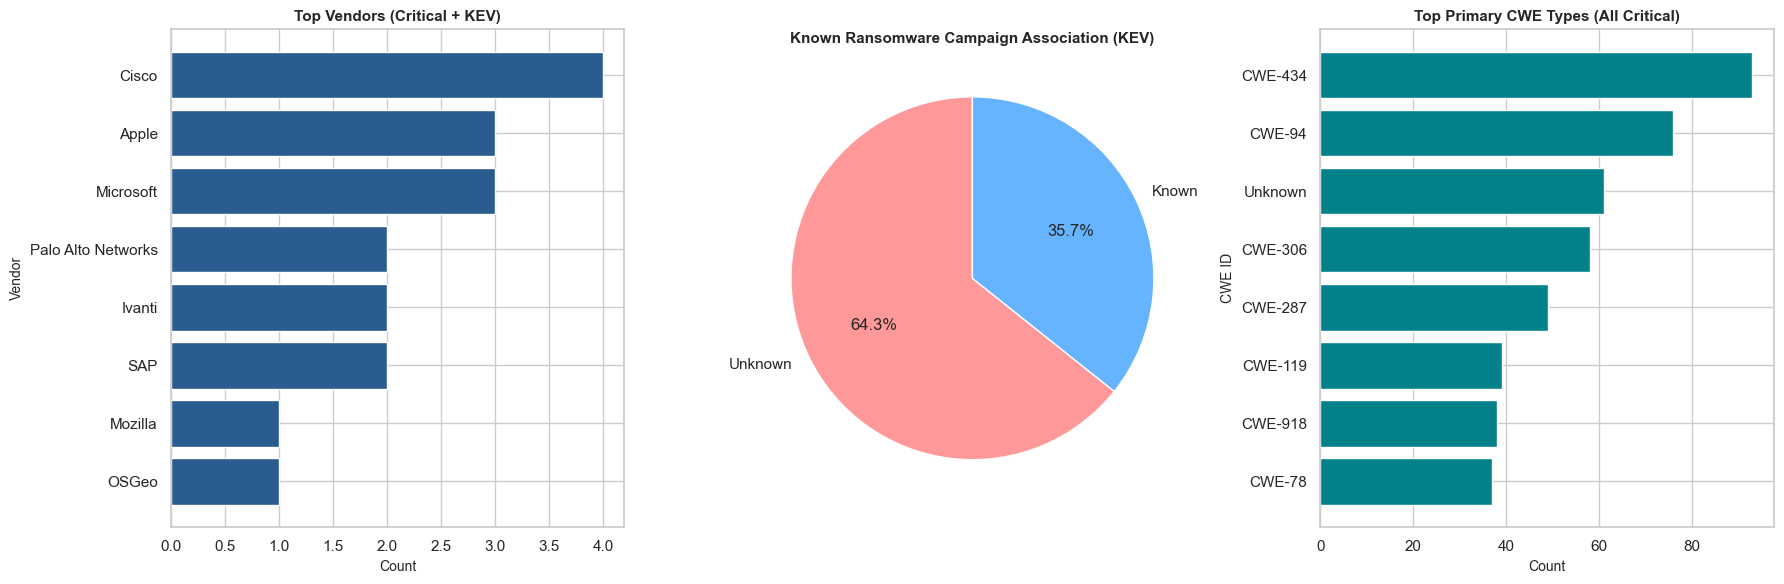

In [7]:
# Cell 5: Direct Interactive Controller (No Javascript / No Webview Lag)

# Change this variable to: 'Summary', 'Prediction', or 'Visualization'
active_mode = 'Visualization'

active_mode = input(f"Current ACTIVE_MODE is set to '{active_mode}'. Change mode (summary/prediction/visualization): ").strip().lower()


def run_pipeline(mode):
  if mode.lower() == 'summary':
    render_summary_mode(top_n=5)
  elif mode.lower() == 'prediction':
    render_prediction_mode(export_csv=True)
  elif mode.lower() == 'visualization':
    render_visualization_mode()
  elif mode.lower() == 'vendor':
    render_vendor_dashboard_mode()
  else:
    print(
        f"Unknown mode '{mode}'. Please choose 'Summary', 'Prediction', or"
        " 'Visualization'."
    )


# Execute selected mode
run_pipeline(active_mode)